# 04 · Which ranking to test

The ranking team proposed putting cheaper hotels first. This notebook compares four ways to
order a search's hotels — reviews first, cheapest first, and two rankings built from the choice
model — on **expected bookings per search** and **expected booking value**, using searches the
models never saw. The comparison follows the decision rule committed before this notebook was
written ([`reports/decision_rule.md`](../reports/decision_rule.md)).

**How a ranking is evaluated offline.** A booking model with an *outside option* ("clicked but
booked nothing") is fitted on 80% of the randomly ordered searches. For each held-out search,
each policy re-arranges the same hotels across the same slots; the model then gives the
probability that each hotel is booked and that nothing is. Because positions were random in
these searches, the model has seen what happens when good hotels land at the top by chance.

**What it cannot do.** Expedia's own ranking cannot be scored: the data does not say what
order Expedia would have shown in these searches.

In [1]:
import os
import sys
from pathlib import Path


def _project_root() -> Path:
    """The folder holding src/hotelrank, wherever the script or notebook was started."""
    here = Path.cwd().resolve()
    for p in (here, *here.parents):
        if (p / "src" / "hotelrank" / "__init__.py").exists():
            return p
    for marker in here.glob("*/src/hotelrank/__init__.py"):
        return marker.parents[2]
    raise FileNotFoundError("run from inside the project folder")


sys.path.insert(0, str(_project_root() / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from hotelrank import audit, choice, policy, position
from hotelrank.data import FIGURES_DIR, ROOT as PROJECT_ROOT, load
from hotelrank.records import show_verdict, write_metrics

N_BOOT = int(os.environ.get("HOTELRANK_N_BOOT", 200))
COLUMNS = ["srch_id", "position", "random_bool", "click_bool", "booking_bool", "price_usd", "prop_starrating",
           "prop_review_score", "prop_brand_bool", "prop_location_score1", "promotion_flag", "prop_id",
           "srch_length_of_stay", "srch_booking_window", "srch_adults_count", "srch_children_count",
           "srch_room_count", "srch_saturday_night_bool"]
df, SOURCE = load(COLUMNS)
flags_path = PROJECT_ROOT / "data" / "interim" / "search_flags.parquet"
if SOURCE == "real" and flags_path.exists():
    flags = pd.read_parquet(flags_path)
else:
    flags = audit.price_flags(df, audit.per_search(df)).reset_index().rename(columns={"index": "srch_id"})
x = position.analysis_sample(df, flags)
del df
x = policy.prepare(choice.add_hotel_mean_price(x[x["random_bool"].astype(bool)], full=x))
test = (x["srch_id"] % 5 == 0).to_numpy()  # the same split as notebook 03's hold-out
fit = policy.fit_booking_model(x[~test])
evalset = policy.make_eval_set(x[test])
print(SOURCE, f"train {fit.n_searches:,} searches, held out {evalset.n_searches:,}; converged={fit.converged}")

real train 91,516 searches, held out 23,165; converged=True


## 1. The booking model

Hotel attributes and position as in notebook 03; the outside option has a constant plus search
covariates (number of results, length of stay, booking window, party size, rooms, Saturday
night). Coefficients on the hotel side differ from notebook 03's booking model because this one
also learns from searches that ended without a booking.

In [2]:
coef = fit.table()
coef.loc[[c for c in policy.HOTEL_ATTRIBUTES + policy.OUTSIDE_COLUMNS if c in coef.index]].round(4)

,beta,se
log_price,-1.0786,0.0361
hotel_mean_log_price,0.5818,0.0425
prop_starrating,0.1621,0.0124
prop_review_score,0.2411,0.0175
no_reviews,0.0232,0.0901
prop_brand_bool,0.2773,0.0212
prop_location_score1,0.0308,0.0071
promotion_flag,0.3759,0.0226
outside,0.0145,0.1196
out_log_n_results,0.7272,0.0199


## 2. Is the evaluator trustworthy?

Two checks on the held-out searches, in the order actually shown:

1. **Calibration.** Predicted booking probability against the observed booking rate, by decile.
2. **Order luck.** The policies gain only if *the order* changes whether a booking happens. In
   each held-out search, compare the predicted probability under the shown order with its
   average over random re-shuffles of the same hotels: positive when good hotels happened to
   land on top. If the model is right, searches with more luck should book more than their
   shuffled average by about the predicted amount (slope 1); if order does not matter, slope 0.

In [3]:
calib = policy.evaluator_calibration(evalset, fit)
luck = policy.order_luck_check(evalset, fit)
overall = {"predicted_booking_rate": float(calib["pred"].mean()), "observed_booking_rate": float(evalset.booked_any.mean())}
print(overall, luck.attrs["slope"])
luck.round(4)

{'predicted_booking_rate': 0.1333115940852581, 'observed_booking_rate': 0.13179365421972805} {'slope': 0.37128441188866257, 'se': 0.3297659109938141, 'ci': [-0.275056773659213, 1.0176255974365382]}


,searches,predicted_uplift,observed_uplift,observed_se
bin,,,,
0,4633,-0.0071,-0.0017,0.0053
1,4633,-0.0017,0.0007,0.0045
2,4633,0.0007,-0.0022,0.0043
3,4633,0.0034,-0.0004,0.0047
4,4633,0.0106,0.0019,0.0055


## 3. The four rankings

Expected bookings and booking value per held-out search, with 95% intervals from 200 replicates
that each draw the model's coefficients from their estimated uncertainty and re-weight the
held-out searches (search-level bootstrap). The logged random order is shown for reference.

In [4]:
result = policy.evaluate(evalset, fit, n_boot=N_BOOT, seed=11)
table = pd.DataFrame({
    k: {"bookings_per_search": b, "bookings_lo": policy.interval(result["draws"][k][:, 0])[0],
        "bookings_hi": policy.interval(result["draws"][k][:, 0])[1], "value_per_search_usd": v,
        "value_lo": policy.interval(result["draws"][k][:, 1])[0], "value_hi": policy.interval(result["draws"][k][:, 1])[1]}
    for k, (b, v) in result["point"].items()}).T
table.round(4)

,bookings_per_search,bookings_lo,bookings_hi,value_per_search_usd,value_lo,value_hi
B1_reviews_first,0.1384,0.1359,0.1406,46.7891,45.5734,48.1652
B2_cheapest_first,0.1369,0.1346,0.1393,35.4356,34.6231,36.4350
M1_most_likely_booked,0.1526,0.1502,0.1552,44.4149,43.1145,45.7617
M2_highest_expected_value,0.1423,0.1400,0.1448,50.4063,48.9994,51.9798
logged_random_order,0.1333,0.1313,0.1355,41.5721,40.5064,42.7881


## 4. The pre-declared decision

Applied mechanically: B\* and M\* are the baseline and the model ranking with the most expected
bookings. Test M\* only if its bookings beat B\*'s with the 95% interval of the difference above
zero **and** its booking value is no more than 2% lower.

In [5]:
decision = policy.apply_decision_rule(result)
decision

{'B_star': 'B1_reviews_first',
 'M_star': 'M1_most_likely_booked',
 'bookings_diff': 0.014187925571289756,
 'bookings_diff_ci': [0.013089040604941466, 0.01537323785544829],
 'bookings_rel_change': 0.10252861337361008,
 'value_rel_change': -0.050742383227667776,
 'condition_1_bookings': True,
 'condition_2_value': False,
 'recommend': 'B1_reviews_first',
 'failed': ['booking value more than 2% lower'],
 'cheapest_first_vs_reviews_first': {'bookings_diff': -0.0014638312726806546,
  'bookings_diff_ci': [-0.0027506076724748254, -1.2489951797152681e-05],
  'value_rel_change': -0.24265294399617776}}

## 5. The other guardrails in the metric framework

`reports/metrics_framework.md` (phase 0) also set two guardrails for any ranking change: the
share of bookings going to hotels with no reviews should not rise above the baseline's, and the
price of the booked hotel should be reported, since a large drop signals revenue risk. Both are
expected values under the booking model; the blend from section 7 is included.

In [6]:
p_hat = policy.Params.from_vector(fit.names, fit.beta)
scores = policy.policy_scores(evalset, p_hat)
scores["blend_lambda_0.3"] = policy.blend_scores(evalset, p_hat, 0.3)
guardrails = pd.DataFrame({k: policy.guardrail_metrics(evalset, p_hat, policy.assign_slots(evalset, s))
                           for k, s in scores.items()}).T
guardrails.loc["logged_random_order"] = policy.guardrail_metrics(evalset, p_hat, evalset.slots)
guardrails.round(4)

,no_review_booking_share,booked_nightly_price_usd
B1_reviews_first,0.0131,150.5779
B2_cheapest_first,0.0281,115.5913
M1_most_likely_booked,0.0126,129.3952
M2_highest_expected_value,0.0133,157.0039
blend_lambda_0.3,0.0123,137.8612
logged_random_order,0.0245,139.4346


## 6. Does the evaluator flatter its own rankings?

The model rankings are built and scored by the same model, which could favour them over the
baselines (a ranking tuned to a model's errors looks good to that model). Cross-fitting checks
this: the training searches are split in half, each half's model builds the rankings and the
other half's model scores them.

In [7]:
crossfit = policy.crossfit_check(x[~test], evalset)
crossfit.round(5)

bookings                         value  \
scoring                   other half's model same model other half's model   
policy                                                                       
B1_reviews_first                     0.13838    0.13838           46.78849   
B2_cheapest_first                    0.13693    0.13693           35.43711   
M1_most_likely_booked                0.15252    0.15260           44.39914   
M2_highest_expected_value            0.14227    0.14239           50.35824   
blend_lambda_0.3                     0.15129    0.15140           47.01686   

                                      
scoring                   same model  
policy                                
B1_reviews_first            46.78849  
B2_cheapest_first           35.43711  
M1_most_likely_booked       44.42672  
M2_highest_expected_value   50.41635  
blend_lambda_0.3            47.05952

## 7. Beyond the rule (exploratory)

The rule picks the model ranking by bookings alone. A family of rankings between M1 (most
likely to be booked) and M2 (highest expected value) shows the trade-off between the two
metrics; these are point estimates and were not part of the pre-declared comparison.

In [8]:
p_hat = policy.Params.from_vector(fit.names, fit.beta)
frontier = []
for lam in np.linspace(0, 1, 11):
    o = policy.outcomes(evalset, p_hat, policy.assign_slots(evalset, policy.blend_scores(evalset, p_hat, lam)))
    frontier.append({"lambda": round(float(lam), 2), "bookings": o["bookings"], "value": o["value"]})
frontier = pd.DataFrame(frontier)
b1 = result["point"]["B1_reviews_first"]
dominates_b1 = frontier[(frontier["bookings"] > b1[0]) & (frontier["value"] > b1[1])]
print(f"blends that beat reviews-first on both metrics: {len(dominates_b1)} of {len(frontier)}")
frontier.round(4)

blends that beat reviews-first on both metrics: 8 of 11


,lambda,bookings,value
0,0.0,0.1526,44.4149
1,0.1,0.1524,45.2572
2,0.2,0.1521,46.1509
3,0.3,0.1514,47.0433
4,0.4,0.1504,47.9028
5,0.5,0.1492,48.6667
6,0.6,0.1478,49.2912
7,0.7,0.1464,49.7631
8,0.8,0.1449,50.0888
9,0.9,0.1436,50.2962


## 8. Figure

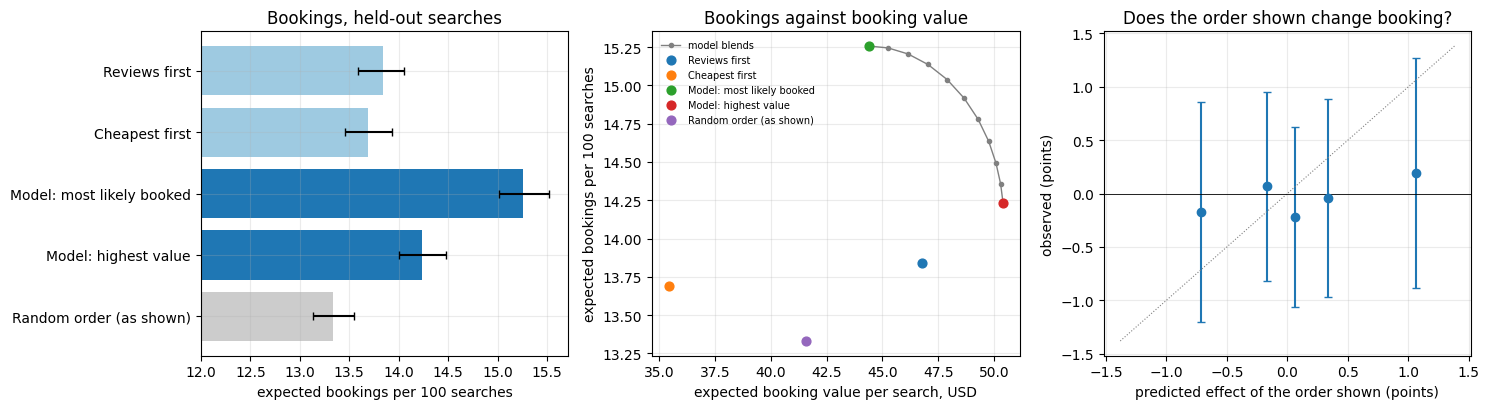

In [9]:
labels = {"B1_reviews_first": "Reviews first", "B2_cheapest_first": "Cheapest first",
          "M1_most_likely_booked": "Model: most likely booked", "M2_highest_expected_value": "Model: highest value",
          "logged_random_order": "Random order (as shown)"}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
order = list(labels)
y = np.arange(len(order))
vals = [table.loc[k, "bookings_per_search"] * 100 for k in order]
err = np.clip([[(table.loc[k, "bookings_per_search"] - table.loc[k, "bookings_lo"]) * 100 for k in order],
               [(table.loc[k, "bookings_hi"] - table.loc[k, "bookings_per_search"]) * 100 for k in order]], 0, None)
axes[0].barh(y, vals, xerr=err, color=["#9ecae1", "#9ecae1", "#1f77b4", "#1f77b4", "#cccccc"], capsize=3)
axes[0].set_yticks(y, [labels[k] for k in order])
axes[0].invert_yaxis()
axes[0].set(xlabel="expected bookings per 100 searches", title="Bookings, held-out searches")
axes[0].set_xlim(min(vals) * 0.9, max(vals) * 1.03)
axes[1].plot(frontier["value"], frontier["bookings"] * 100, color="grey", lw=1, marker=".", label="model blends")
for k in order:
    b, v = result["point"][k]
    axes[1].scatter(v, b * 100, s=40, label=labels[k], zorder=3)
axes[1].set(xlabel="expected booking value per search, USD", ylabel="expected bookings per 100 searches",
            title="Bookings against booking value")
axes[1].legend(frameon=False, fontsize=7)
axes[2].errorbar(luck["predicted_uplift"] * 100, luck["observed_uplift"] * 100, yerr=1.96 * luck["observed_se"] * 100,
                 fmt="o", capsize=3)
lim = max(abs(luck["predicted_uplift"]).max(), abs(luck["observed_uplift"]).max()) * 100 * 1.3
axes[2].plot([-lim, lim], [-lim, lim], ls=":", color="grey", lw=0.8)
axes[2].axhline(0, color="black", lw=0.6)
axes[2].set(xlabel="predicted effect of the order shown (points)", ylabel="observed (points)",
            title="Does the order shown change booking?")
for ax in axes:
    ax.grid(alpha=0.25)
fig.tight_layout()

In [10]:
def draws_ci(k, col):
    lo, hi = policy.interval(result["draws"][k][:, col])
    return [round(lo, 6), round(hi, 6)]


record = {
    "sample": {"train_searches": fit.n_searches, "heldout_searches": evalset.n_searches, "n_boot": N_BOOT},
    "booking_model": {"names": fit.names, "beta": [round(float(b), 6) for b in fit.beta],
                      "se": [round(float(s), 6) for s in fit.se], "converged": fit.converged,
                      "ridge": policy.RIDGE, "mcfadden_r2": round(fit.mcfadden_r2, 4)},
    "evaluator": {**{k: round(v, 5) for k, v in overall.items()},
                  "calibration": {int(i): {"pred": round(float(r.pred), 5), "obs": round(float(r.obs), 5)}
                                  for i, r in calib.iterrows()},
                  "order_luck": {int(i): {c: round(float(r[c]), 6) for c in luck.columns} for i, r in luck.iterrows()},
                  "order_luck_slope": {k: (round(v, 4) if not isinstance(v, list) else [round(z, 4) for z in v])
                                       for k, v in luck.attrs["slope"].items()}},
    "policies": {k: {"bookings_per_search": round(b, 6), "bookings_ci": draws_ci(k, 0),
                     "value_per_search_usd": round(v, 4), "value_ci": draws_ci(k, 1)}
                 for k, (b, v) in result["point"].items()},
    "decision": decision,
    "frontier_exploratory": frontier.round(6).to_dict(orient="records"),
    "guardrails": {k: {c: round(float(v), 5) for c, v in r.items()} for k, r in guardrails.iterrows()},
    "crossfit": {k: {f"{m}_{'same' if s == 'same model' else 'cross'}": round(float(r[(m, s)]), 6)
                     for m, s in r.index} for k, r in crossfit.iterrows()},
}
out_path = write_metrics("04_policy_evaluation", record, SOURCE)
print("wrote", out_path.relative_to(PROJECT_ROOT) if SOURCE == "real" else out_path.name)
if SOURCE == "real":
    fig.savefig(FIGURES_DIR / "04_policy_evaluation.png", dpi=150, bbox_inches="tight")

wrote reports\metrics\04_policy_evaluation.json


## Verdict

Which ranking to take into an A/B test, by the rule written down before the evaluation. The verdict is rendered from `record`, the same dictionary written to
`reports/metrics/04_policy_evaluation.json`, so the summary cannot drift from the analysis above.

In [11]:
dec, pol, ev = record["decision"], record["policies"], record["evaluator"]
b_star, m_star = dec["B_star"], dec["M_star"]
cf = dec["cheapest_first_vs_reviews_first"]
base = pol[b_star]
both = [f for f in record["frontier_exploratory"]
        if f["bookings"] > base["bookings_per_search"] and f["value"] > base["value_per_search_usd"]]
best = max(both, key=lambda f: f["bookings"]) if both else None
sl = ev["order_luck_slope"]
verdict = [
    f"By the pre-declared rule (`reports/decision_rule.md`) the ranking to test is: {labels[dec['recommend']]}.",
    f"The strongest model ranking, {labels[m_star]}, raises expected bookings {dec['bookings_rel_change']:+.1%} "
    f"against {labels[b_star]} (95% interval of the difference [{dec['bookings_diff_ci'][0]:+.4f}, "
    f"{dec['bookings_diff_ci'][1]:+.4f}] per search) and changes booking value {dec['value_rel_change']:+.1%}."
    + (f" It fails: {'; '.join(dec['failed'])}." if dec["failed"] else " It passes both conditions."),
    f"Cheapest first against reviews first: bookings {cf['bookings_diff']:+.5f} per search "
    f"[{cf['bookings_diff_ci'][0]:+.5f}, {cf['bookings_diff_ci'][1]:+.5f}] and booking value {cf['value_rel_change']:+.0%}. "
    + ("Putting cheaper hotels up loses on both." if cf["bookings_diff_ci"][1] < 0 and cf["value_rel_change"] < 0
       else "The evidence does not show cheapest first losing on both."),
    (f"Exploratory, outside the rule: {len(both)} of {len(record['frontier_exploratory'])} blends of the two model "
     f"rankings beat {labels[b_star]} on both metrics; the best on bookings (weight {best['lambda']:.1f} on value) gives "
     f"{best['bookings']:.4f} bookings and ${best['value']:.2f} per search. That makes it a candidate arm for the A/B "
     "test, not a result." if best else
     f"Exploratory, outside the rule: no blend of the model rankings beats {labels[b_star]} on both metrics."),
    (lambda g, gb: f"Framework guardrails: bookings at hotels with no reviews are {g['B1_reviews_first']['no_review_booking_share']:.2%} "
     f"under reviews first, {g['B2_cheapest_first']['no_review_booking_share']:.2%} under cheapest first and "
     f"{gb['no_review_booking_share']:.2%} under the λ = 0.3 blend; the blend's booked hotel costs "
     f"${gb['booked_nightly_price_usd']:.0f} a night against ${g['B1_reviews_first']['booked_nightly_price_usd']:.0f} under "
     "reviews first, so it wins on value through more bookings, not dearer ones.")(
        record["guardrails"], record["guardrails"]["blend_lambda_0.3"]),
    (lambda c: f"The evaluator does not flatter its own rankings: scored by a model fitted on the other half of the "
     f"training searches, {labels[m_star]} gives {c[m_star]['bookings_cross']:.4f} bookings per search against "
     f"{c[m_star]['bookings_same']:.4f} when the same model builds and scores it.")(record["crossfit"]),
    f"Caveat: the evaluator is calibrated overall ({ev['predicted_booking_rate']:.2%} predicted against "
    f"{ev['observed_booking_rate']:.2%} observed), but the order-luck slope is {sl['slope']:.2f} "
    f"(95% CI [{sl['ci'][0]:.2f}, {sl['ci'][1]:.2f}])"
    + (", which includes zero: the logged data cannot confirm that reordering changes booking. Every gain above is "
       "model-implied, and only an online test can confirm it." if sl["ci"][0] <= 0 <= sl["ci"][1] else
       ". Reordering does move booking in the logged data, which supports the evaluator's mechanism."),
]
show_verdict("Phase 4 verdict: ranking policies", verdict,
             "Phase 5 writes the decision memo and sizes the A/B test.")

### Phase 4 verdict: ranking policies

1. By the pre-declared rule (`reports/decision_rule.md`) the ranking to test is: Reviews first.
2. The strongest model ranking, Model: most likely booked, raises expected bookings +10.3% against Reviews first (95% interval of the difference [+0.0131, +0.0154] per search) and changes booking value -5.1%. It fails: booking value more than 2% lower.
3. Cheapest first against reviews first: bookings -0.00146 per search [-0.00275, -0.00001] and booking value -24%. Putting cheaper hotels up loses on both.
4. Exploratory, outside the rule: 8 of 11 blends of the two model rankings beat Reviews first on both metrics; the best on bookings (weight 0.3 on value) gives 0.1514 bookings and \$47.04 per search. That makes it a candidate arm for the A/B test, not a result.
5. Framework guardrails: bookings at hotels with no reviews are 1.31% under reviews first, 2.81% under cheapest first and 1.23% under the λ = 0.3 blend; the blend's booked hotel costs \$138 a night against \$151 under reviews first, so it wins on value through more bookings, not dearer ones.
6. The evaluator does not flatter its own rankings: scored by a model fitted on the other half of the training searches, Model: most likely booked gives 0.1525 bookings per search against 0.1526 when the same model builds and scores it.
7. Caveat: the evaluator is calibrated overall (13.33% predicted against 13.18% observed), but the order-luck slope is 0.37 (95% CI [-0.28, 1.02]), which includes zero: the logged data cannot confirm that reordering changes booking. Every gain above is model-implied, and only an online test can confirm it.

**Next:** Phase 5 writes the decision memo and sizes the A/B test.